# Joint bias in $A_B$ and $F$ from neglecting hyperillumination

This is the analysis of `AB_Bias.ipynb`, extended to heat redistribution. The noiseless "data" (Asimov dataset) are a `hyperillum` phase curve with Bond albedo $A_{B,\rm true}$ and no heat redistribution. They are fitted with `naive_redist`, the point-source model with Kreidberg & Loeb (2016) heat redistribution, with $A_B$, $F$ and the baseline free. The truth has $F = 0$, so the fitted $F$ is itself the bias in $F$. For comparison, the $A_B$-only fit of `AB_Bias` (`naive`, which equals `naive_redist` at $F = 0$) is shown alongside.

In [1]:
import numpy as np
import os
import contextlib, io
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from HItargets_utils import *

# Exoplanet Archive (to populate bias map)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Target, as in AB_Bias.ipynb
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"
period, incl, ecc, w, r1, r2, R, T2_eff, a_AU = planet.args

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from target data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
A_B = 3/2 * Ag # 0.42

# ASSUMPTION (!)
# Model for band-integrated albedo in the observing band (MIR)
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR
# A_model = ScaledBandAlbedo(1.) # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate).

In [4]:
# Filter to be used
instrument, instrument_pandexo = "JWST_NIRSpec.G395H_NRS1", "NIRSpec G395H"  # "MIRI/LRS", "MIRI LRS"
filter_path = filter_loc(instrument)
lambda_range = filter_lambda(instrument)

In [5]:
# Instrument Parameters
n_bins = 27 # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes]
sigma_1min = rms_1min(run_pandexo(planet.name, instrument_pandexo, t14_h=planet.T14), planet.T14, filter_lambda(instrument))
n_orbits = 5 # number of orbits observed (3 orbits has been done)

PandExo inputs for TOI-2431 b  [instrument=NIRSpec G395H]
    period     = 0.2242       d                <- pl_orbper
    rp_rearth  = 1.534        R_earth          <- pl_rade
    rs_rsun    = 0.651        R_sun            <- st_rad
    teff       = 4109         K                <- st_teff
    logg       = 4.68         log cgs          <- st_logg
    metal      = -0.02        log Fe/H         <- st_met
    t14_h      = 0.7475       h                <- override
    mag        = 7.554        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All good', 'Group Number Too High?': '

In [6]:
# Plot style and colours (F: blue ramp, hyperillumination: orange, A_B-only fit: grey, target: green star) come from simple_bias_analysis
set_plot_style()
F_small = np.array([0., 0.005, 0.01, 0.015, 0.02])   # heat redistributions compared with the truth in 1.

## Detectability and parameter bias analysis

The noise per minute comes from PandExo for the chosen instrument and target (printed below).

In [7]:
l1, l2 = lambda_range
with contextlib.redirect_stdout(io.StringIO()):   # mute "no stellar models provided, using blackbody approximation"
    stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=filter_path)

A_B_true = A_B  # 3/2 * Ag(Zieba2022) = 0.42
F_true = 0.     # the hyperillumination truth has no heat redistribution, so a fitted F IS its bias

# context for the bias-analysis functions imported from simple_bias_analysis.py (T_floor=200, bounds=(0.0, 0.6), F_bounds=(0.0, 0.5) by default)
cfg = FittingConfig(planet=planet, stellar_grid=stellar_grid, filter_path=filter_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_B=u_B, u=u)


sigma_bin = cfg.sigma_bin # [ppm]
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")


Noise Level (1min) = 38.3 ppm
period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin = 5.0 ppm


### 1. Pure Detectability

These plots compare `hyperillum` with `naive_redist` at the true $A_B$ for small redistributions, $F$ = 0 to 0.02. At $F = 0$, `naive_redist` is the naive curve of `AB_Bias`.

In [8]:
# Full phase curves (reflected + thermal) at the true A_B: hyperillumination, and naive_redist for each F in F_small
curve_kw = dict(u=u, u_B=u_B, filter_path=filter_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150)

def curves(model, F):
    t_, pc, _ = full_PhaseCurve(planet, lambda_range, insolation_model=model, F=F, **curve_kw)
    _, lc, _ = full_PhaseCurve(planet, lambda_range, insolation_model=model, F=F, include_transit=False, **curve_kw)   # transit removed: phase modulation + occultation only
    return t_, pc, lc

runs = [("hyperillum", None)] + [("naive_redist", F) for F in F_small]
out = Parallel(n_jobs=-1, backend="loky")(delayed(curves)(m, F) for m, F in runs)
get_reusable_executor().shutdown(wait=True)   # free the memory SPIDERMAN leaks in the workers
t_k, pc_k, lc_k = out[0]
redist_curves = dict(zip(F_small, out[1:]))   # F -> (t, phase curve, light curve)

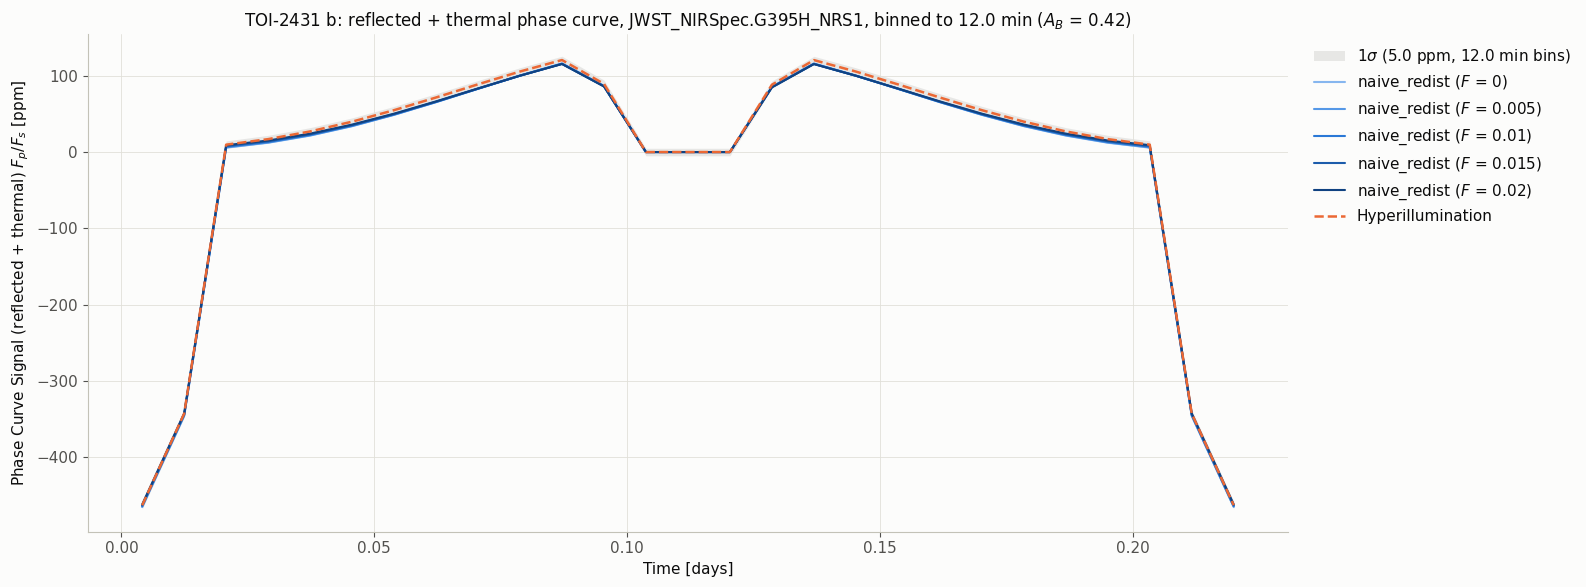

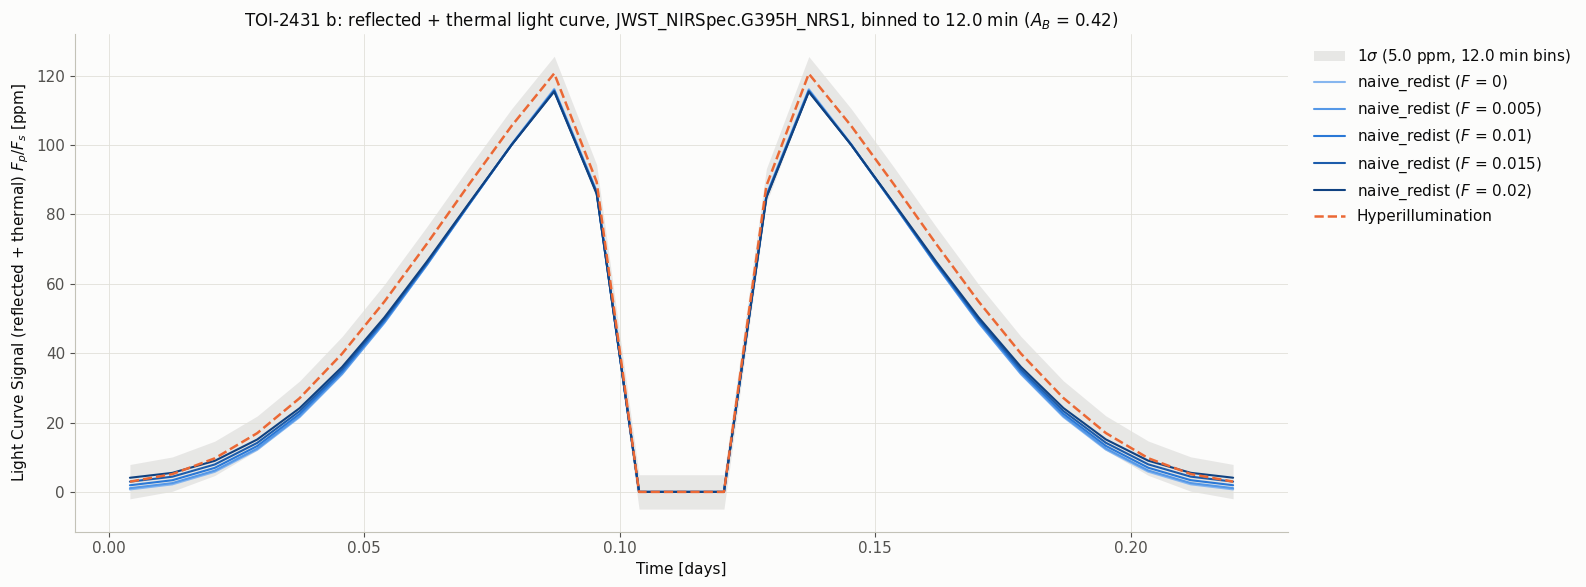

In [9]:
# signal [ppm] of each curve for the two views: the phase curve with the transit, and the light curve without it
views = [("phase curve", r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]", lambda pc, lc: (pc - 1) * 1e6),
         ("light curve", r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]", lambda pc, lc: lc * 1e6)]

for name, ylabel, signal in views:
    tb_k, yb_k = bin_curve(t_k, signal(pc_k, lc_k), minutes_binning)

    plt.figure(figsize=(16, 6))
    plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color=INK_2, alpha=0.12, lw=0, label=rf"$1\sigma$ ({sigma_bin:.1f} ppm, {minutes_binning:.1f} min bins)")
    for F, col in zip(F_small, F_COLORS):
        t_F, pc_F, lc_F = redist_curves[F]
        plt.plot(*bin_curve(t_F, signal(pc_F, lc_F), minutes_binning), lw=1.5, color=col, label=f"naive_redist ($F$ = {F:g})")
    plt.plot(tb_k, yb_k, lw=1.8, ls="--", color=C_HI, label="Hyperillumination", zorder=5)

    plt.xlabel("Time [days]")
    plt.ylabel(ylabel)
    plt.title(f"{planet.name}: reflected + thermal {name}, {instrument}, binned to {minutes_binning:.1f} min ($A_B$ = {A_B:.2f})")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.))
    plt.tight_layout()
    plt.show()

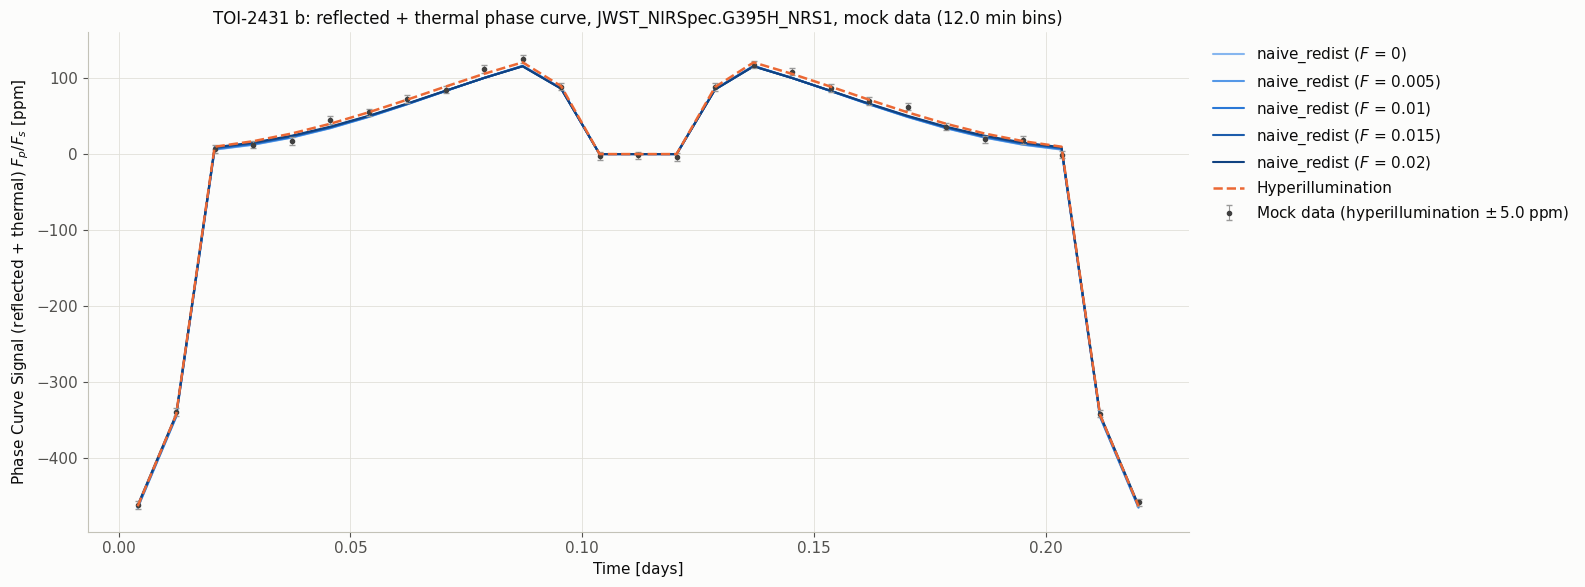

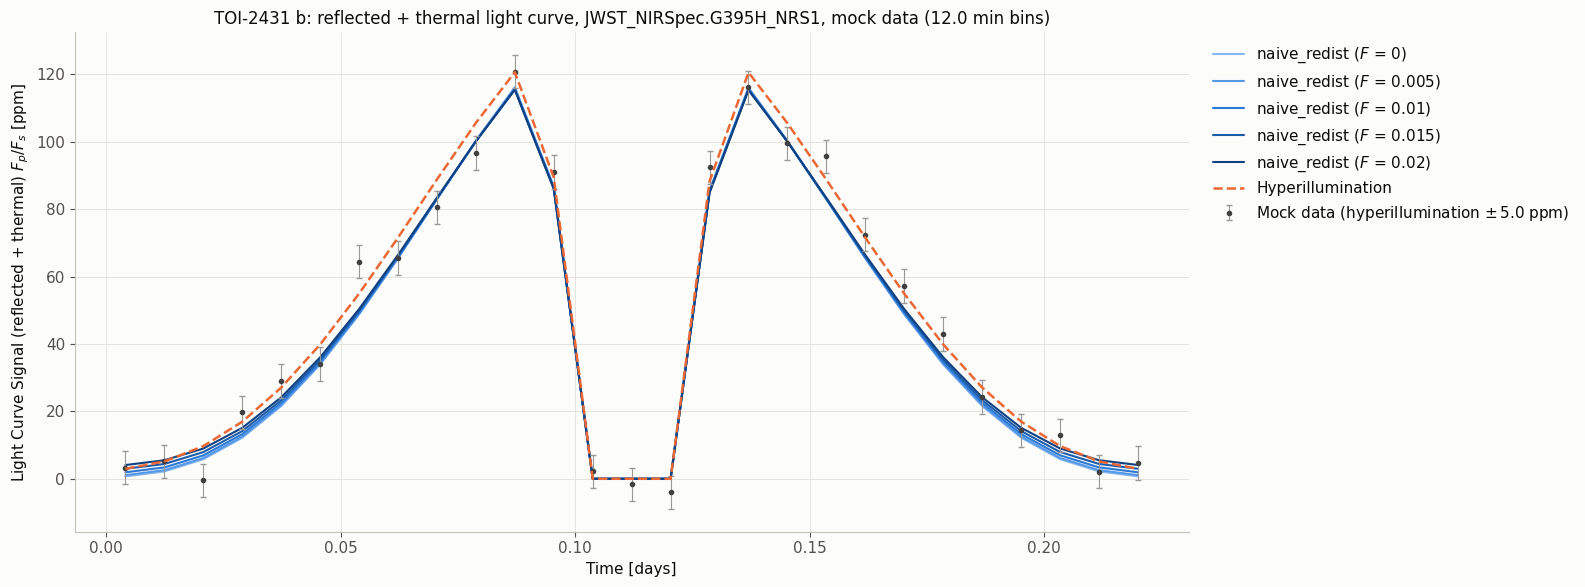

In [10]:
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

for name, ylabel, signal in views:
    tb_k, yb_k = bin_curve(t_k, signal(pc_k, lc_k), minutes_binning)   # hyperillumination model, binned [ppm]
    y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)          # mock data ~ N(hyperillum, sigma_bin)

    plt.figure(figsize=(16, 6))
    plt.errorbar(tb_k, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.1f}$ ppm)", **MOCK_KW)
    for F, col in zip(F_small, F_COLORS):
        t_F, pc_F, lc_F = redist_curves[F]
        plt.plot(*bin_curve(t_F, signal(pc_F, lc_F), minutes_binning), lw=1.5, color=col, label=f"naive_redist ($F$ = {F:g})")
    plt.plot(tb_k, yb_k, lw=1.8, ls="--", color=C_HI, label="Hyperillumination", zorder=6)
    plt.xlabel("Time [days]")
    plt.ylabel(ylabel)
    plt.title(f"{planet.name}: reflected + thermal {name}, {instrument}, mock data ({minutes_binning:.1f} min bins)")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.))
    plt.tight_layout()
    plt.show()

### 2. Bias in recovered $A_B$ and $F$ when hyperillumination is neglected - 2-Parameter Fit

In [11]:
# demo: fit naive (A_B only, as in AB_Bias) and naive_redist (A_B and F) to the hyperillumination truth and report the recovered biases
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

# sqrt(chi2) is S_perp, the truth-to-manifold distance in sigma_bin units — NOT a sigma under any standard test.
# Fitted-vs-fitted discrimination: E[Lambda] = S_perp^2, sd = 2*S_perp, so the significance is S_perp/2 = 0.88 sigma. As goodness of fit: S_perp^2/sqrt(2*(n_bins-2)) = 0.39 sigma. Neither is the 1.76 printed. bias/sigma is the criterion; this line is a distance.
for free_offset in (True, False):
    A_fit, chi2, rms = fit_naive(cfg, truth, free_offset=free_offset)
    A_fit2, F_fit2, chi2_2, rms_2 = fit_redist(cfg, truth, free_offset=free_offset, A_B_start=A_fit)
    T_night = float(surface_temperature(np.pi, planet, "naive_redist", A_B=A_fit2, F=F_fit2))   # nightside temperature the joint fit implies (the truth's antistellar point is at 0 K)
    print(f"free_offset={free_offset}   ({cfg.n_orbits} orbits, {cfg.n_bins} bins)")
    print(f"   A_B only : A_B {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} ({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  "
          f"chi2={chi2:.3f}  resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma")
    print(f"   A_B and F: A_B {A_B_true:.3f} -> {A_fit2:.3f}  bias={A_fit2-A_B_true:+.3f} ({100*(A_fit2-A_B_true)/A_B_true:+.1f}%)  "
          f"chi2={chi2_2:.3f}  resid_rms={rms_2:.2f} ppm  significance={np.sqrt(chi2_2):.2f} sigma")
    print(f"              F {F_true:g} -> {F_fit2:.4f} (bias={F_fit2-F_true:+.4f}, implied nightside T = {T_night:.0f} K)   "
          f"chi2 improvement from freeing F: {chi2 - chi2_2:.3f}\n")

free_offset=True   (5 orbits, 27 bins)
   A_B only : A_B 0.420 -> 0.394  bias=-0.026 (-6.1%)  chi2=3.098  resid_rms=1.68 ppm  significance=1.76 sigma
   A_B and F: A_B 0.420 -> 0.358  bias=-0.062 (-14.8%)  chi2=1.163  resid_rms=1.03 ppm  significance=1.08 sigma
              F 0 -> 0.0215 (bias=+0.0215, implied nightside T = 821 K)   chi2 improvement from freeing F: 1.935

free_offset=False   (5 orbits, 27 bins)
   A_B only : A_B 0.420 -> 0.353  bias=-0.067 (-16.1%)  chi2=7.734  resid_rms=2.65 ppm  significance=2.78 sigma
   A_B and F: A_B 0.420 -> 0.360  bias=-0.060 (-14.2%)  chi2=1.169  resid_rms=1.03 ppm  significance=1.08 sigma
              F 0 -> 0.0208 (bias=+0.0208, implied nightside T = 813 K)   chi2 improvement from freeing F: 6.565



free offset="False" is not really meaningful, since the normalization has an error.

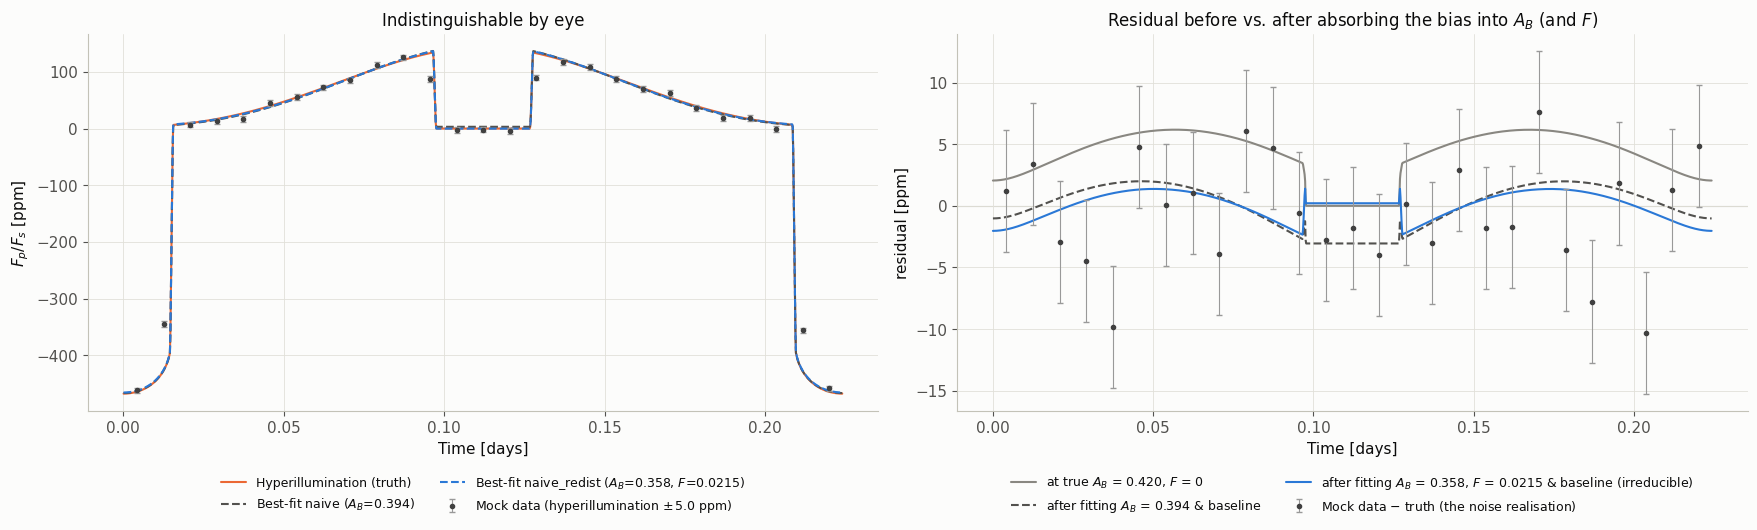

In [12]:
# before vs after absorbing the bias into A_B (naive) or into A_B and F (naive_redist)
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
A_fit2, F_fit2, _, _ = fit_redist(cfg, truth, A_B_start=A_fit)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]   # at the true values: A_B_true, F = 0
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()
redist_f  = model_pcurve(cfg, "naive_redist", A_fit2, F=F_fit2)[1]
redist_f  = redist_f + (truth - redist_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(43).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
# left: truth vs both best fits
ax[0].errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.1f}$ ppm)", **MOCK_KW)
ax[0].plot(t_, truth,    lw=1.5, color=C_HI, label="Hyperillumination (truth)")
ax[0].plot(t_, naive_f,  lw=1.5, ls="--", color=C_NAIVE, label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax[0].plot(t_, redist_f, lw=1.5, ls="--", color=C_REDIST, label=f"Best-fit naive_redist ($A_B$={A_fit2:.3f}, $F$={F_fit2:.4f})")
ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_xlabel("Time [days]")
ax[0].set_title("Indistinguishable by eye")
# right: all residuals on one axes, with the same mock data as the noise the bias has to beat
ax[1].axhline(0., color=AXIS, lw=.8, zorder=1)
ax[1].errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **MOCK_KW)
ax[1].plot(t_, truth - naive_0,  lw=1.5, color=MUTED, label=rf"at true $A_B$ = {A_B_true:.3f}, $F$ = 0")
ax[1].plot(t_, truth - naive_f,  lw=1.5, ls="--", color=C_NAIVE, label=rf"after fitting $A_B$ = {A_fit:.3f} & baseline")
ax[1].plot(t_, truth - redist_f, lw=1.5, color=C_REDIST, label=rf"after fitting $A_B$ = {A_fit2:.3f}, $F$ = {F_fit2:.4f} & baseline (irreducible)")
ax[1].set_ylabel("residual [ppm]"); ax[1].set_xlabel("Time [days]")
ax[1].set_title(r"Residual before vs. after absorbing the bias into $A_B$ (and $F$)")
for a_ in ax: a_.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.tight_layout()
plt.show()

The $\chi^2$ landscape of the joint fit is shown below. It uses the same noiseless residual as `fit_redist` (baseline free) on an $(A_B, F)$ grid. The contours mark $\Delta\chi^2 = 2.30$ and $6.18$ above the minimum: models inside them could not be told apart from the best fit at 68 % and 95 % with this observation.

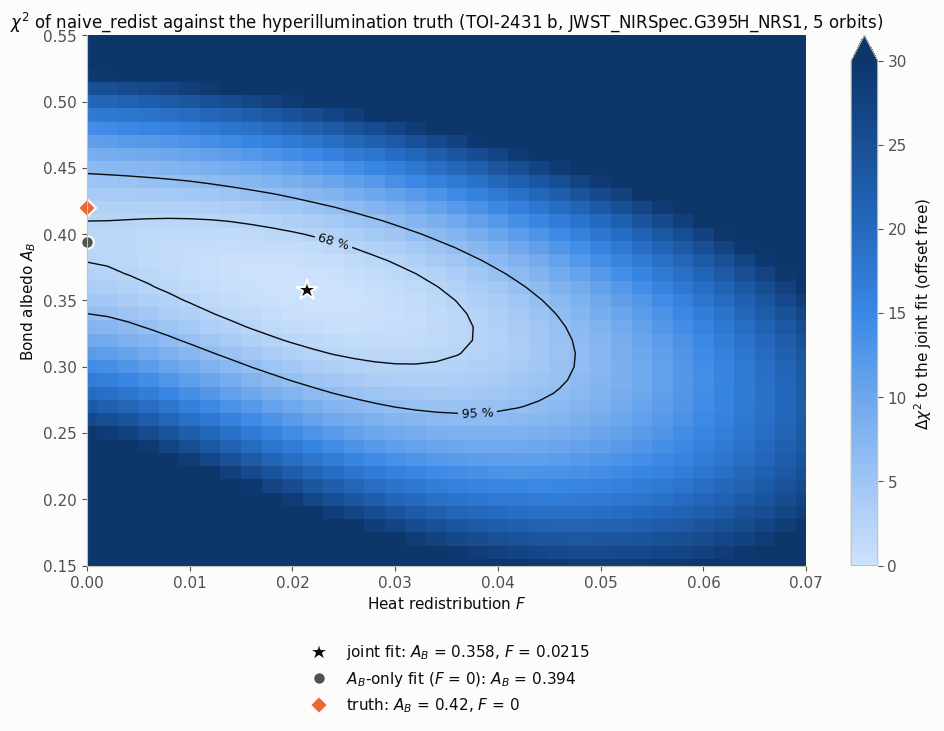

68 % region on the grid: A_B in [0.31, 0.41],  F <= 0.036


In [13]:
F_MAX = 0.07   # plotted F range: both contours close at F ~ 0.055
AB_grid = np.linspace(0.15, 0.55, 41)
F_grid = np.linspace(0., F_MAX, 36)
d_chi2 = chi2_landscape(cfg, truth, AB_grid, F_grid) - fit_chi2(cfg, truth, "naive_redist", A_fit2, F=F_fit2)   # relative to the joint best fit
# d_chi2 is referenced to the NM fit, not to the grid minimum, and plot_chi2_landscape has vmin=0 — an underconverged Nelder-Mead fit would be invisible. print(d_chi2.min()) must be >= 0.

fig, ax = plot_chi2_landscape(F_grid, AB_grid, d_chi2, F_MAX)
ax.plot(F_fit2, A_fit2, "*", ms=16, color=INK, mec="#fcfcfb", mew=1.5, label=f"joint fit: $A_B$ = {A_fit2:.3f}, $F$ = {F_fit2:.4f}")
ax.plot(0., A_fit, "o", ms=9, color=C_NAIVE, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"$A_B$-only fit ($F$ = 0): $A_B$ = {A_fit:.3f}")
ax.plot(F_true, A_B_true, "D", ms=9, color=C_HI, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"truth: $A_B$ = {A_B_true:.2f}, $F$ = 0")
ax.set_title(f"$\\chi^2$ of naive_redist against the hyperillumination truth ({planet.name}, {instrument}, {cfg.n_orbits} orbits)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

(A_lo, A_hi), F_hi = chi2_region(d_chi2, AB_grid, F_grid)
print(f"68 % region on the grid: A_B in [{A_lo:.2f}, {A_hi:.2f}],  F <= {F_hi:.3f}")

### 3. Bias vs. true Bond albedo $A_B$

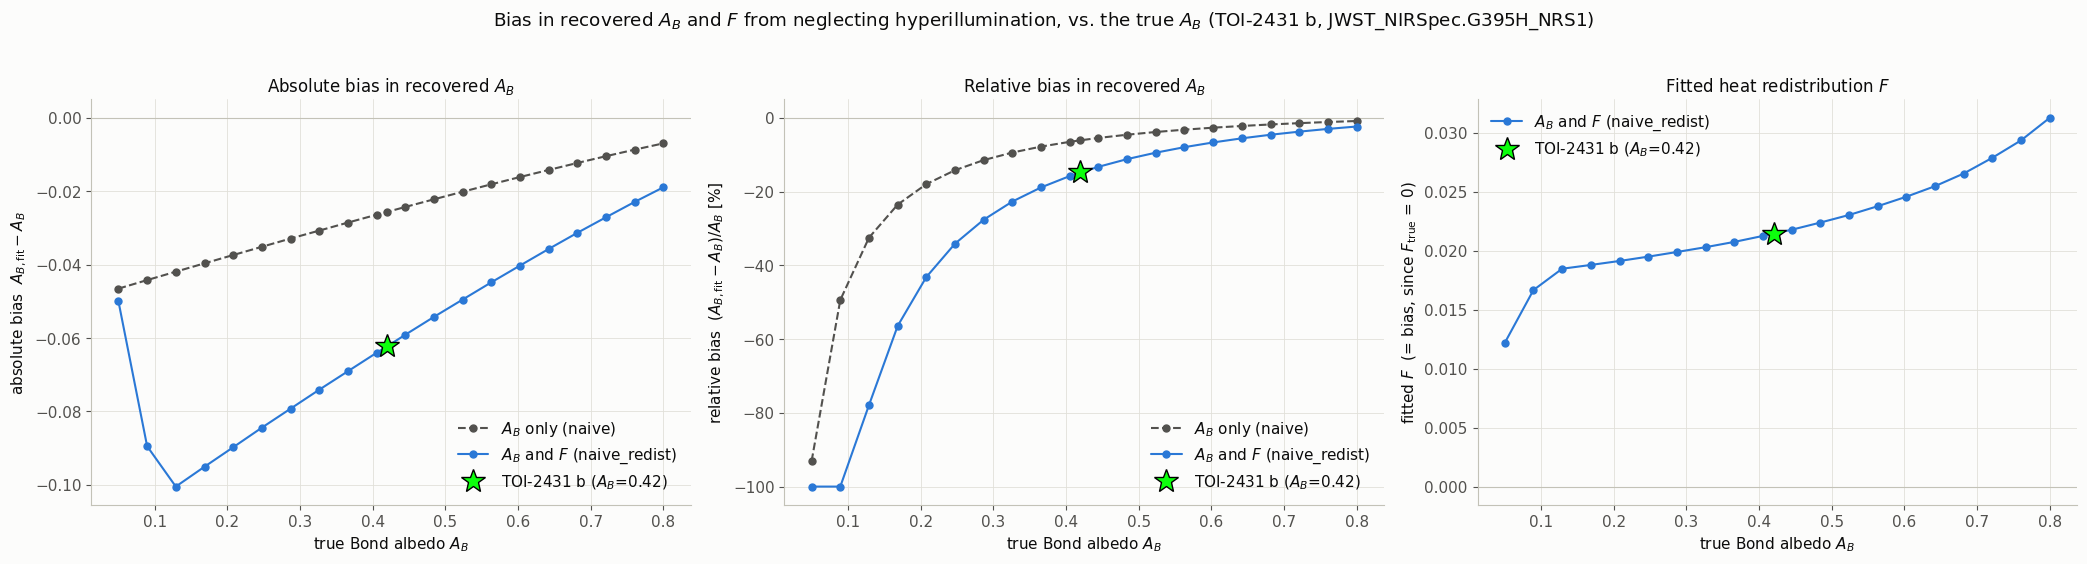

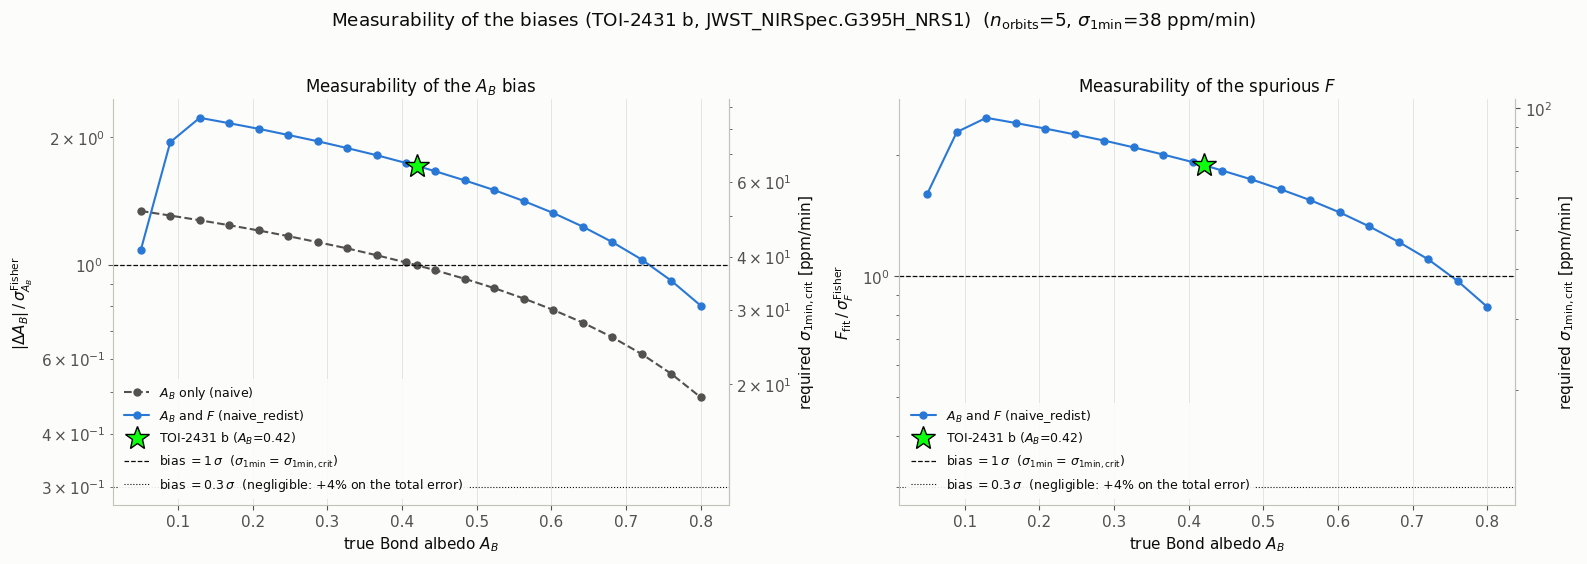

at TOI-2431 b: A_B-only bias -0.026,  joint bias -0.062 with F = 0.0215
A_B only fit never rails at A_B = 0
joint    fit rails at A_B = 0 for true A_B <= 0.09
elsewhere: F from 0.0185 to 0.0313,  joint / A_B-only bias from 2.4 to 2.7

|bias|/sigma_A_B at TOI-2431 b: 1.00 (A_B only), 1.71 (joint)   ->  sigma_1min_crit = 65.5 ppm/min vs 38.3 delivered  (0.6x finer, or 2 orbits instead of 5)
spurious redistribution: F = 0.0215 +- 0.0114  ->  1.89 sigma   (F_true = 0, so this is the false-atmosphere significance)


In [14]:
# Vary the TRUE Bond albedo and refit both models at each value (single target geometry, free baseline; free_offset=False is not meaningful here -- see 2.).
# Bias = fit - truth; the truth has F = 0, so the fitted F is the bias in F. Fisher sigmas (baseline marginalised) turn the biases into a measurability.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))
# No rail check here (unlike bias_cell), so the true A_B <= 0.09 points where the joint fit sits at the A_B = 0 floor enter the curves with a one-sided derivative — that is the kink at the left edge of both panels. Mask them.
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=True)
bias_naive, sig_naive = sweep["naive"]["bias_A_B"], sweep["naive"]["sigma_A_B"]
bias_joint, F_joint, sig_joint, sig_F = (sweep["naive_redist"][k] for k in ("bias_A_B", "F_fit", "sigma_A_B", "sigma_F"))
bs_naive, _ = measurability(bias_naive, sig_naive, cfg.sigma_1min)             # systematic in units of the statistical error bar, at the CURRENT sigma_1min
bs_joint, crit_joint = measurability(bias_joint, sig_joint, cfg.sigma_1min)
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

# Freeing F widens A_B's MARGINAL sigma as well as enlarging its bias, so the two effects partly cancel -- which is why the ratio, not the bias alone, is the decision number.
target_label = f"{planet.name} ($A_B$={A_B_true:.2f})"
plot_joint_bias_vs_true_AB(A_B_grid, sweep, i0, target_label=target_label,
                           title=f"Bias in recovered $A_B$ and $F$ from neglecting hyperillumination, vs. the true $A_B$ ({planet.name}, {instrument})")
# Measurability: |Delta A_B| / sigma_A_B (left) and the spurious F / sigma_F (right); the right axes give the per-minute precision at which each bias is a 1-sigma effect.
plot_joint_measurability(A_B_grid, sweep, i0, cfg, target_label=target_label,
                         title=f"Measurability of the biases ({planet.name}, {instrument})")

railed = {name: A_B_grid + b < 1e-3 for name, b in (("A_B only", bias_naive), ("joint", bias_joint))}   # fits sitting at the A_B = 0 floor
ok = ~railed["joint"] & ~railed["A_B only"]
print(f"at {planet.name}: A_B-only bias {bias_naive[i0]:+.3f},  joint bias {bias_joint[i0]:+.3f} with F = {F_joint[i0]:.4f}")
for name, r in railed.items():
    print(f"{name:8s} fit rails at A_B = 0 for true A_B <= {A_B_grid[r].max():.2f}" if r.any() else f"{name:8s} fit never rails at A_B = 0")
print(f"elsewhere: F from {F_joint[ok].min():.4f} to {F_joint[ok].max():.4f},  joint / A_B-only bias from {np.min(bias_joint[ok] / bias_naive[ok]):.1f} to {np.max(bias_joint[ok] / bias_naive[ok]):.1f}")

fac = cfg.sigma_1min / crit_joint[i0]   # = 1 / bias_sigma; how much finer the photometry must get before the bias is a 1-sigma effect
print(f"\n|bias|/sigma_A_B at {planet.name}: {bs_naive[i0]:.2f} (A_B only), {bs_joint[i0]:.2f} (joint)"
      f"   ->  sigma_1min_crit = {crit_joint[i0]:.1f} ppm/min vs {cfg.sigma_1min:.1f} delivered"
      f"  ({fac:.1f}x finer, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits})")
print(f"spurious redistribution: F = {F_joint[i0]:.4f} +- {sig_F[i0]:.4f}  ->  {F_joint[i0] / sig_F[i0]:.2f} sigma   (F_true = 0, so this is the false-atmosphere significance)")

At the target, freeing $F$ more than doubles the albedo bias: $-0.062$ instead of $-0.026$, with a fitted $F = 0.021$. The same holds across the grid. Wherever neither fit rails, the joint bias is 2.4–2.7 times the $A_B$-only bias, and the fitted $F$ rises with the true $A_B$ from 0.0185 to 0.0313.

For true $A_B \le 0.09$ the joint fit rails at the physical floor $A_{B,\rm fit}=0$. Its absolute bias then saturates at $-A_B$ and its relative bias at $-100\%$, and $F$ drops to about 0.012 at $A_B = 0.05$. $A_B$ is underestimated and $F$ overestimated throughout.

### 4. In which regimes does hyperillumination matter? Bias maps over (a/Rs, T_eff)

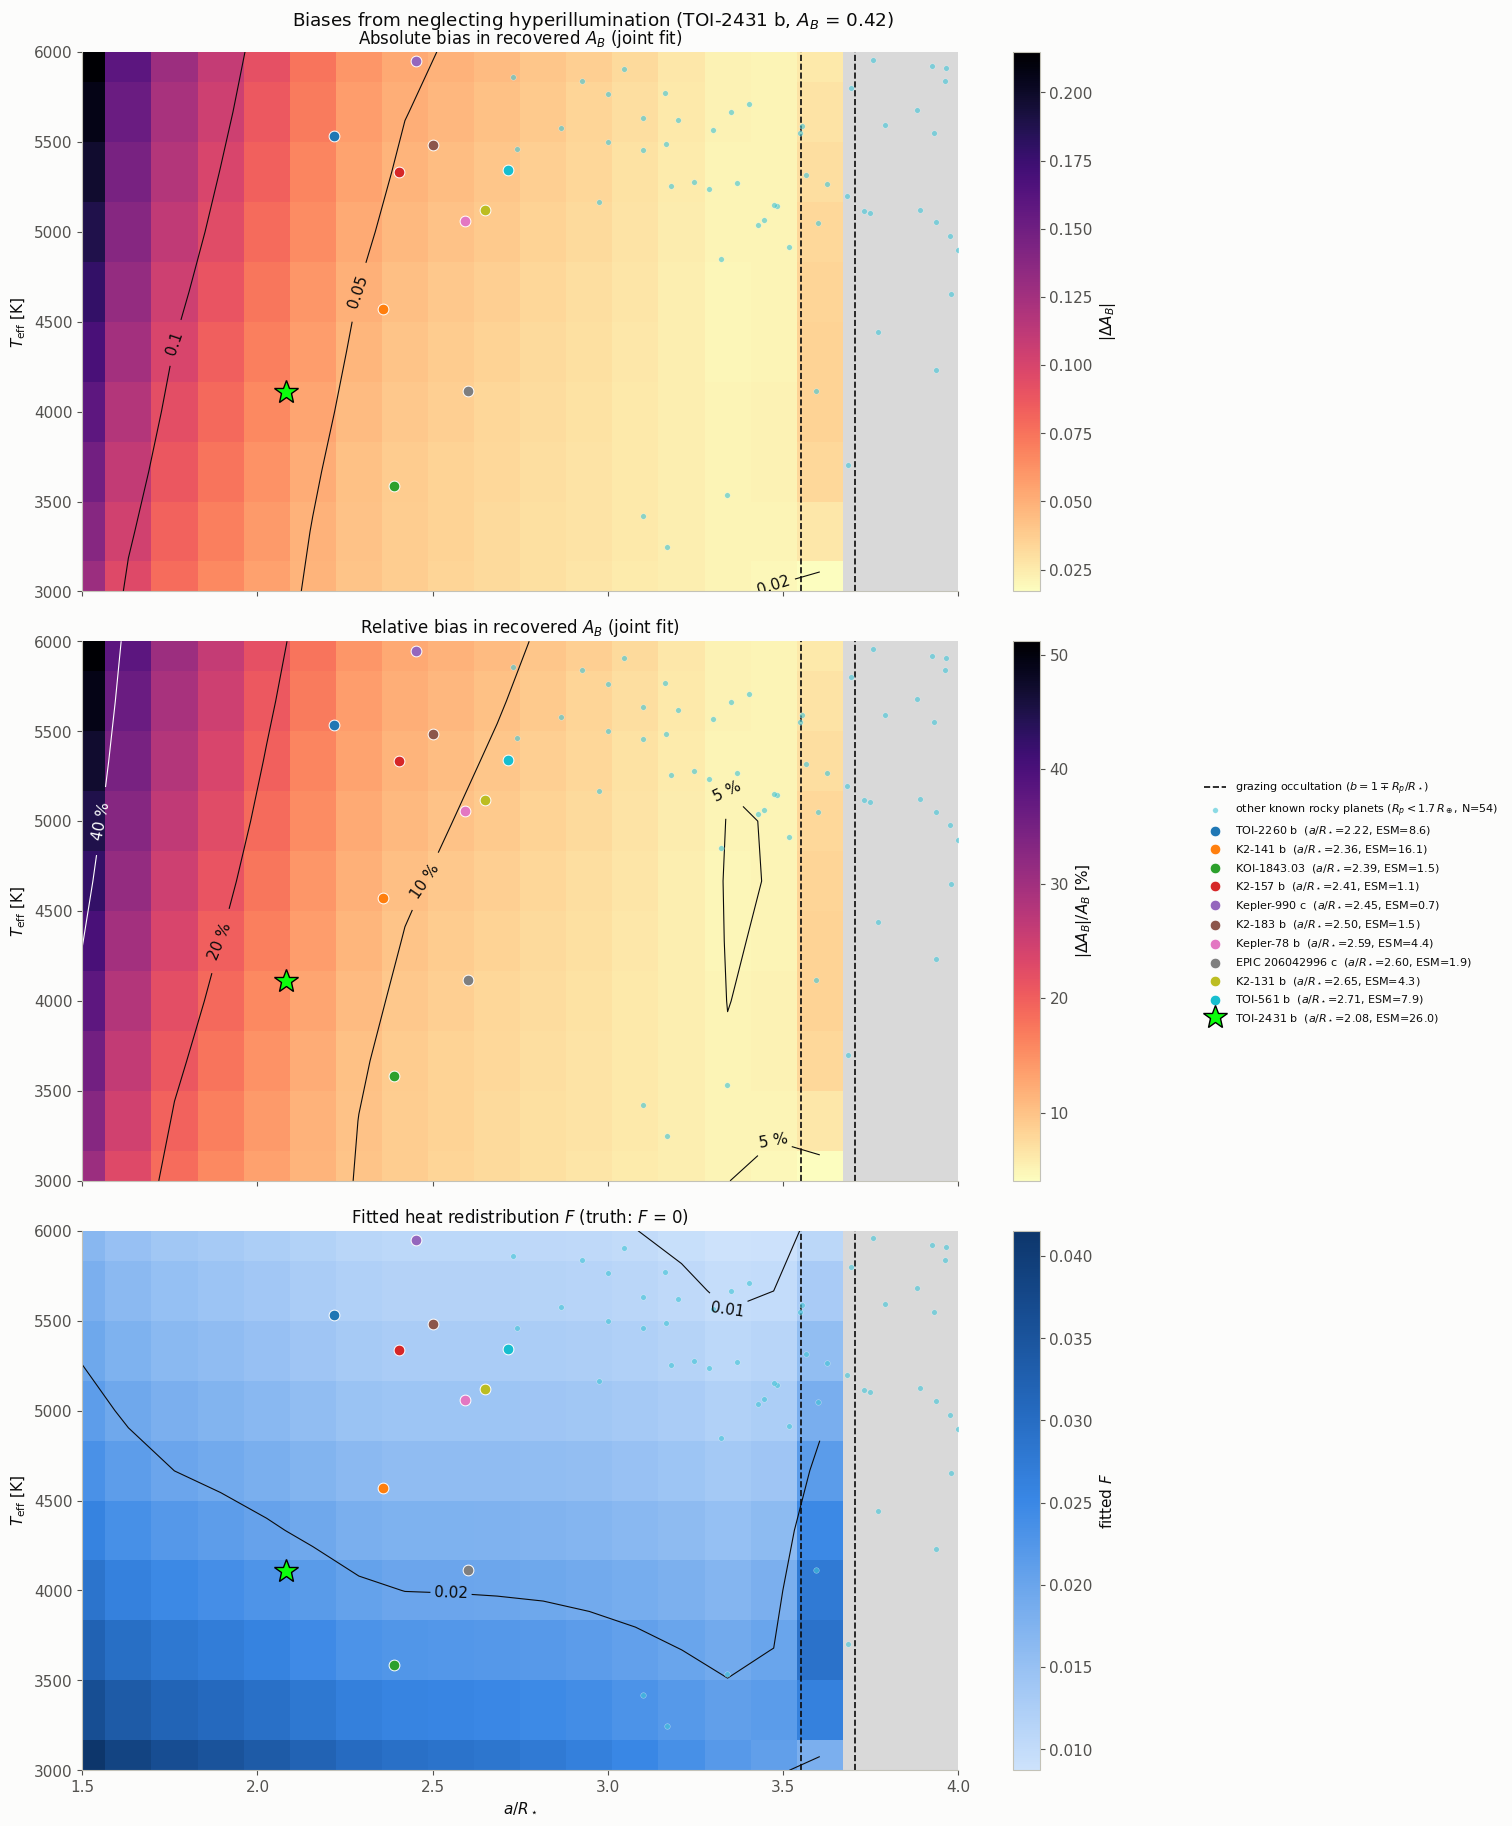

occulting, non-railed cells: 170 of 200;  Delta A_B in [-0.215, -0.017] = [-51.2, -4.0] % of A_B,  F in [0.0087, 0.0415]
railed: 0,  without occultation: 30


In [15]:
# TODO: For careful evaluation of physical parameter space, add Roche limit to map
# The biases are pure model-degeneracy quantities, so these maps are independent of the noise level sigma and of the target's brightness. The cells are independent -> run in parallel.
a_rs_grid  = map_grid(1.5, 4.0, 20, include=planet.R / planet.r2)
T_eff_grid = map_grid(3000., 6000., 10, include=planet.T2_eff)
kw = dict(n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_pcurve keeps the naive terminator spline stable at this resolution

bias_map, F_map = bias_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", redist=True, **kw)
plot_bias_maps(a_rs_grid, T_eff_grid, bias_map, A_B_true, planet, AGG, "st_teff", r"$T_{\rm eff}$ [K]",
               rp_rs_of=lambda y: np.full_like(y, planet.r1 / planet.r2), F_map=F_map)

Grey cells are geometries without an occultation, right of the dashed lines. The maps keep TOI-2431 b's inclination of 74°, so the impact parameter $b = (a/R_\star)\cos i$ passes $1 + R_p/R_\star$ at $a/R_\star \approx 3.7$. Without the eclipse nothing anchors the flux level, and $A_B$ and $F$ become degenerate. No occulting cell railed.

Over the 170 occulting cells, the joint fit underestimates $A_B$ by 0.017 to 0.215 (4 % to 51 % of the true value) and returns $F$ = 0.009 to 0.042. The relative map is the absolute one divided by the fixed true $A_B = 0.42$, so the two share their pattern:
- $|\Delta A_B|$ is largest at small $a/R_\star$ and high $T_{\rm eff}$, and drops below 0.05 beyond $a/R_\star \approx$ 2.1–2.5, depending on $T_{\rm eff}$.
- The fitted $F$ is largest for cool stars at small $a/R_\star$. It falls below 0.01 only for the hottest stars at $a/R_\star \gtrsim 3.3$.
- Within the grazing zone (between the dashed lines) the partial occultation only weakly constrains the fit.

### 5. In which regimes does hyperillumination matter? Bias maps over (a/Rs, Rp/Rs)

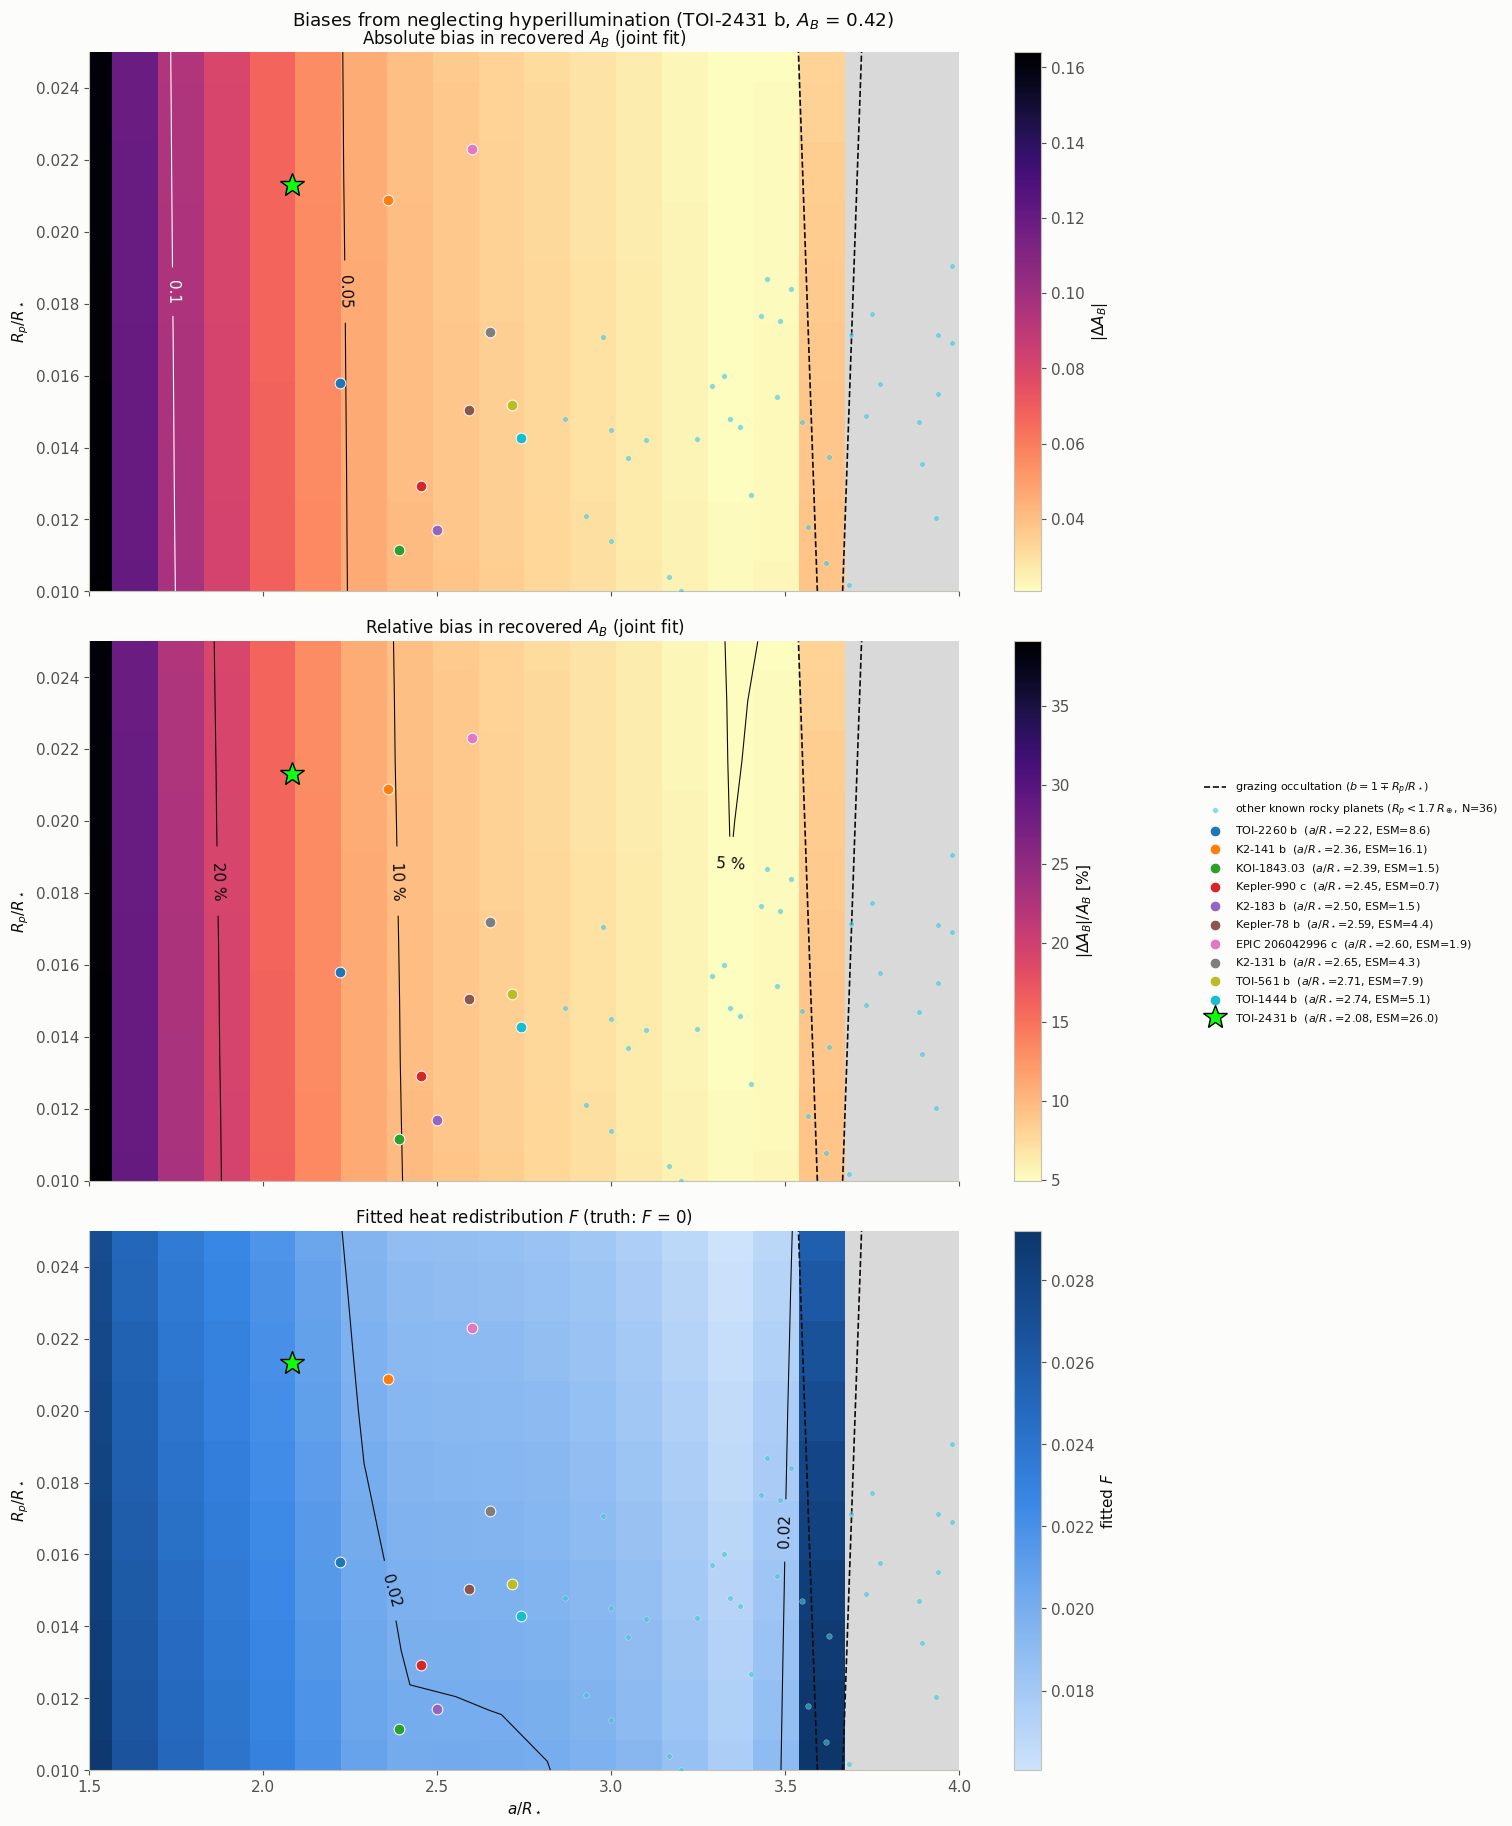

occulting, non-railed cells: 170 of 200;  Delta A_B in [-0.164, -0.021] = [-39.1, -4.9] % of A_B,  F in [0.0161, 0.0292]
railed: 0,  without occultation: 30


In [16]:
# Grid box, widened by map_grid where the target itself falls outside it, so the notebook's own `planet` is always on its own map.
a_rs_grid  = map_grid(1.5, 4.0, 20, include=planet.R / planet.r2)
rp_rs_grid = map_grid(0.01, 0.025, 10, include=planet.r1 / planet.r2)
kw = dict(n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_pcurve keeps the naive terminator spline stable at this resolution

bias_map, F_map = bias_map_grid(cfg, A_B_true, a_rs_grid, rp_rs_grid, "rp_rs", redist=True, **kw)
plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, A_B_true, planet, AGG, "pl_ratror", r"$R_p/R_\star$", rp_rs_of=lambda y: y, F_map=F_map)

Grey cells and dashed lines are as in 4; here the occultation limit shifts slightly with $R_p/R_\star$. Over the 170 occulting cells, the joint fit underestimates $A_B$ by 0.021 to 0.164 (5 % to 39 %) and returns $F$ = 0.016 to 0.029:
- $|\Delta A_B|$ depends almost only on $a/R_\star$ and drops below 0.05 beyond $a/R_\star \approx 2.2$.
- The fitted $F$ is highest at the smallest $a/R_\star$ and in the grazing zone, and lowest near $a/R_\star \approx 3.4$. It depends weakly on $R_p/R_\star$.

Both biases keep their sign throughout the map: $A_B$ is always underestimated and $F$ always overestimated.

### 6. Per-planet decision: does the biased $A_B$ (and the spurious $F$) matter for the closest-in rocky planets?

The 10 smallest-$a/R_\star$ rocky planets of the map in 5., each re-fitted with its **own** geometry and its **own** PandExo noise for this instrument, at the same assumed $A_B$.
The truth has $F = 0$, so the fitted $F$ **is** the bias: a non-zero value is heat redistribution that the data do not contain, i.e. hyperillumination masquerading as an atmosphere.
The decision columns (`bias`, `sigma`, `bias_sigma`, `sigma_1min_crit`) refer to $A_B$ by default; pass `quantity="F"` to `planet_bias_table` to put them on the spurious $F$ instead.
$\sigma_{1\rm min, crit} = \sigma_{1\rm min}\,|{\rm bias}|/\sigma$ is then the precision at which that bias would be reported as a $1\sigma$ effect -- and the planets where the delivered precision already beats it are the ones where a naive fit would report an albedo (or a redistribution) that is not there.

A planet whose Fisher $\sigma$ is at or above the flat-prior std $(hi - lo)/\sqrt{12}$ of the fit bounds (0.289 for $A_B \in [0, 1]$, dashed line) is marked *unconstrained* (hatched bars): there ${\rm bias}/\sigma$ is a ratio to a meaningless number, so neither "needs hyperillumination" nor "naive OK" applies.


Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation


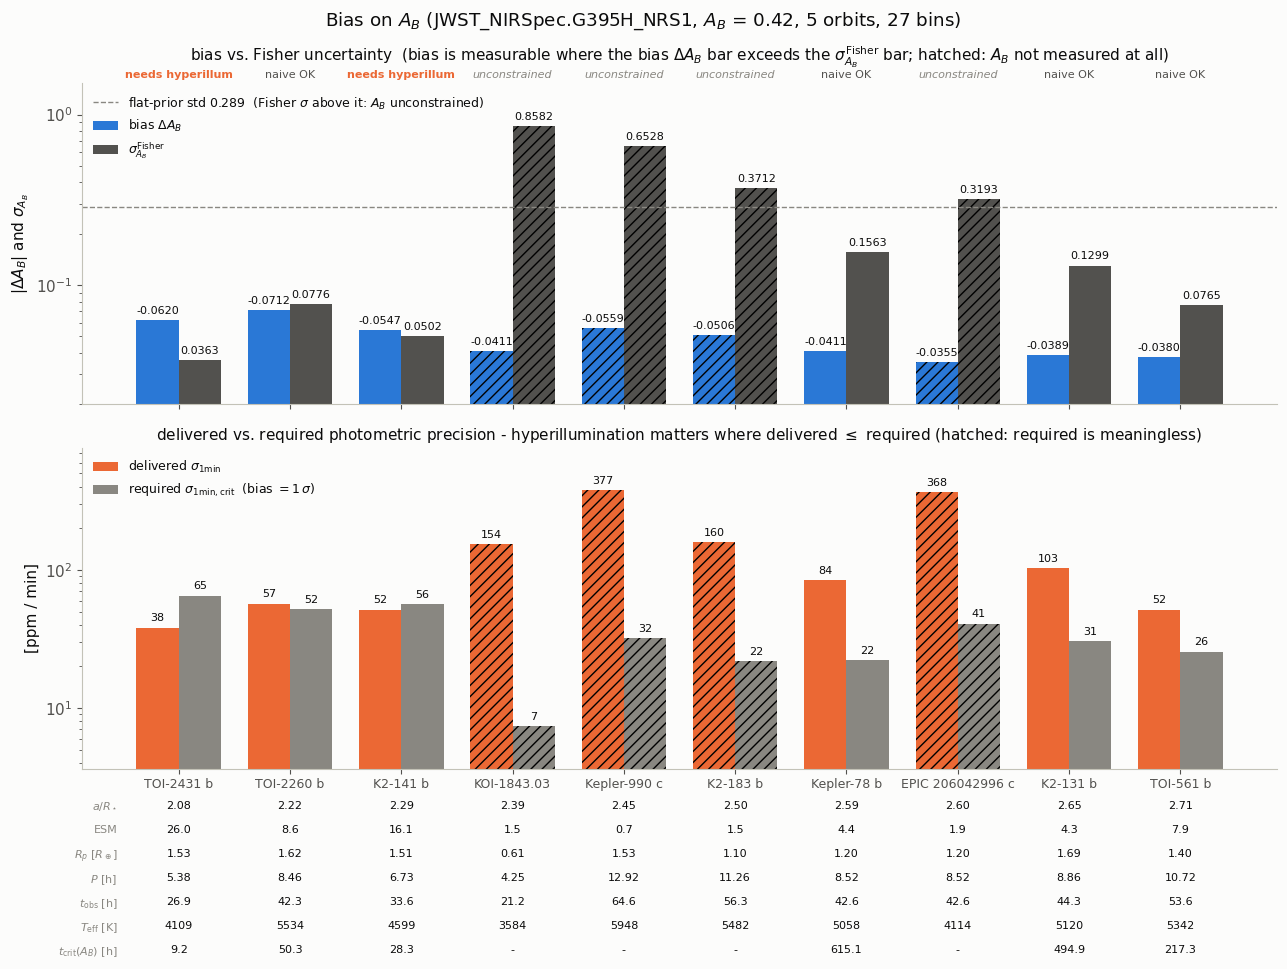

2 of 10 needs hyperillum: TOI-2431 b, K2-141 b
4 of 10 naive OK: TOI-2260 b, Kepler-78 b, K2-131 b, TOI-561 b
4 of 10 unconstrained: KOI-1843.03, Kepler-990 c, K2-183 b, EPIC 206042996 c
            name  a_rs    esm  bias_A_B  sigma_A_B   F_fit  sigma_F  bias_sigma  sigma_1min  sigma_1min_crit          verdict
      TOI-2431 b 2.081  25.96    -0.062    0.03635 0.02158  0.01135       1.706       38.29            65.31 needs hyperillum
      TOI-2260 b 2.219  8.632  -0.07118    0.07764 0.01254   0.0129      0.9168       57.16            52.41         naive OK
        K2-141 b 2.292  16.12   -0.0547    0.05018 0.01622  0.01395        1.09       51.71            56.37 needs hyperillum
     KOI-1843.03 2.389   1.47   -0.0411     0.8582 0.02546   0.4514      0.0479       154.1            7.381    unconstrained
    Kepler-990 c 2.453 0.6968  -0.05587     0.6528 0.01065   0.1125     0.08559       377.3            32.29    unconstrained
        K2-183 b   2.5  1.483  -0.05061     0.3712  0.011

In [17]:
# Same sample definition overlay_planets draws on the maps (rocky, Rp < 1.7 R_Earth, inside the map box), so figure and map cannot disagree.
# The target is NOT excluded here: this figure compares it against its neighbours instead of marking it separately.
top10 = rocky_sample(AGG, "pl_ratror", (rp_rs_grid[0], rp_rs_grid[-1]), a_rs_lim=(a_rs_grid[0], a_rs_grid[-1])).nsmallest(10, "a_over_r2")
planets10 = hi_planets_by_name(list(top10.pl_name))

# One PandExo run per planet: NOT cached and seconds per target, so keep this dict rather than recomputing it.
sigma10 = rms_1min_sample(top10.pl_name, instrument, instrument_pandexo)

# redist=True -> the joint (A_B, F) fit; quantity defaults to "A_B", so bias / sigma / bias_sigma / sigma_1min_crit all refer to the albedo bias (pass quantity="F" for the spurious redistribution instead).
tab_redist = planet_bias_table(cfg, A_B_true, planets10, sigma10, redist=True, AGG=AGG, **kw)   # AGG only supplies the ESM for the tick labels
# Two figures from the same joint fit, each with its bias / precision pair and the a/Rs panel: A_B first, then the spurious F.
title_tail = f"({instrument}, $A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits, {cfg.n_bins} bins)"
fig, ax = plot_planet_bias_bars(tab_redist, quantities=("A_B",), grid=False, log_bias=True, title=f"Bias on $A_B$ {title_tail}")   # log_bias: an unconstrained sigma (~1) would otherwise flatten the measurable ones (~0.05)
plt.show()
# fig, ax = plot_planet_bias_bars(tab_redist, quantities=("F",), grid=False, title=f"Bias on F {title_tail}")
# plt.show()

# Three-way verdict (bias_verdict): bias >= 1 sigma needs hyperillumination; below it naive is OK only where sigma_A_B is below the flat-prior std of the fit bounds, otherwise A_B is simply unconstrained.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED):
    sel = tab_redist[tab_redist.verdict == v]
    print(f"{len(sel)} of {len(tab_redist)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_redist[["name", "a_rs", "esm", "bias_A_B", "sigma_A_B", "F_fit", "sigma_F", "bias_sigma", "sigma_1min", "sigma_1min_crit", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
